In [1]:
import pandas as pd
import numpy as np
# from vis.utils_motifs import motif_to_fwords
from collections import Counter
import ast
import matplotlib.pyplot as plt
import torch
import math
import seaborn as sns
from pathlib import Path

In [34]:
RESULT_DIR = Path("../results/run_GCN_persuade_wan_cooc_qwen2515b_wan-w5_nf-count+freq+emb_ew-wan_sp-random_L2_H64_sum_lr0.001_seed2026")
motif_file = RESULT_DIR / "atob_motcom005.csv" 
two_edge_motifs_file = RESULT_DIR / "atob_mot2edg005.pth" 
edge_motifs_file = RESULT_DIR / "atob_motedg005.pth" 
results_file = RESULT_DIR / "explanations_none_object.pth"

In [9]:
fwords_df = pd.read_csv("../data/function_words_277.csv")
fwords = fwords_df["word"].tolist()

In [10]:
def motif_to_fwords(motif, function_words):
    """
    Convert motifs to function words.
    """
    if isinstance(motif, str):
        motif = ast.literal_eval(motif)

    return " ".join(
        f"({function_words[u]}, {function_words[v]})"
        for u, v in motif
    )

In [11]:
df_motifs = pd.read_csv(motif_file)
df_motifs

,motif,human_present,human_selected,human_rate,machine_present,machine_selected,machine_rate,difference
0,"((86, 92), (92, 47))",3,0,0.000000,1,1,1.0,1.0
1,"((0, 5), (0, 43))",5,0,0.000000,1,1,1.0,1.0
2,"((87, 0), (87, 36))",9,0,0.000000,1,1,1.0,1.0
3,"((92, 110), (110, 65))",1,0,0.000000,1,1,1.0,1.0
4,"((100, 5), (109, 5))",12,0,0.000000,1,1,1.0,1.0
...,...,...,...,...,...,...,...,...
4335,"((112, 74), (112, 80))",21,1,0.047619,0,0,NaN,NaN
4336,"((112, 76), (113, 112))",3,1,0.333333,0,0,NaN,NaN
4337,"((112, 78), (113, 112))",4,1,0.250000,0,0,NaN,NaN
4338,"((112, 109), (112, 113))",8,1,0.125000,0,0,NaN,NaN


In [12]:
human_selected = df_motifs["human_selected"] > 0
machine_selected = df_motifs["machine_selected"] > 0

human_only = (human_selected & ~machine_selected).sum()
machine_only = (~human_selected & machine_selected).sum()
shared = (human_selected & machine_selected).sum()

total = (human_selected | machine_selected).sum()

print(f"TOtal unique selected motifs: {total}")
print(f"Human only: {human_only}")
print(f"Machine only: {machine_only}")
print(f"Shared: {shared}")

TOtal unique selected motifs: 4340
Human only: 3639
Machine only: 685
Shared: 16


In [13]:
h = df_motifs[
    (df_motifs["human_selected"] > 0) &
    (df_motifs["machine_selected"] == 0)
]

m = df_motifs[
    (df_motifs["human_selected"] == 0) &
    (df_motifs["machine_selected"] > 0)
]

print("Human-only motifs selected once:",
      (h["human_selected"] == 1).sum())

print("Machine-only motifs selected once:",
      (m["machine_selected"] == 1).sum())

Human-only motifs selected once: 3596
Machine-only motifs selected once: 681


In [ ]:
results_motifs = torch.load(
    edge_motifs_file,
    map_location="cpu",
    weights_only=False
)

In [18]:
results_2edge = torch.load(
    two_edge_motifs_file,
    map_location="cpu",
    weights_only=False
)

In [35]:
results = torch.load(
    results_file,
    map_location="cpu",
    weights_only=False
)

In [ ]:
df_graphs = pd.DataFrame(results_motifs)
df_graphs

,row,label,pred,motifs,num_motifs
0,13,0,0,"[((41, 5), (42, 41)), ((41, 5), (47, 5)), ((41...",9
1,17,0,0,"[((8, 101), (77, 8)), ((10, 80), (80, 38)), ((...",16
2,20,0,0,"[((5, 101), (10, 101)), ((5, 101), (42, 5)), (...",18
3,22,0,0,"[((2, 61), (2, 109)), ((2, 61), (5, 2)), ((2, ...",9
4,28,0,0,"[((0, 97), (97, 101)), ((0, 97), (109, 0)), ((...",16
...,...,...,...,...,...
355,2372,1,1,[],0
356,2379,1,1,"[((28, 80), (28, 92)), ((28, 80), (75, 28)), (...",5
357,2381,1,1,"[((3, 56), (37, 56)), ((7, 0), (7, 92)), ((7, ...",7
358,2383,1,1,"[((5, 61), (24, 61)), ((5, 61), (43, 5)), ((5,...",7


In [20]:
df_graphs = df_graphs[
    df_graphs["label"] == df_graphs["pred"]
]

df_graphs["class"] = df_graphs["label"].map({
    0: "Human",
    1: "Machine"
})

display(
    df_graphs.groupby("class")["num_motifs"].agg(
        ["count", "sum", "mean", "median", "min", "max"]
    )
)

,count,sum,mean,median,min,max
class,,,,,,
Human,180,3699,20.550000,16.0,0,91
Machine,178,705,3.960674,3.0,0,14


In [29]:
df_result = pd.DataFrame(results)
df_result

,row,label,pred,motifs,num_motifs
0,13,0,0,"[((41, 5), (42, 41)), ((41, 5), (47, 5)), ((41...",9
1,17,0,0,"[((8, 101), (77, 8)), ((10, 80), (80, 38)), ((...",16
2,20,0,0,"[((5, 101), (10, 101)), ((5, 101), (42, 5)), (...",18
3,22,0,0,"[((2, 61), (2, 109)), ((2, 61), (5, 2)), ((2, ...",9
4,28,0,0,"[((0, 97), (97, 101)), ((0, 97), (109, 0)), ((...",16
...,...,...,...,...,...
355,2372,1,1,[],0
356,2379,1,1,"[((28, 80), (28, 92)), ((28, 80), (75, 28)), (...",5
357,2381,1,1,"[((3, 56), (37, 56)), ((7, 0), (7, 92)), ((7, ...",7
358,2383,1,1,"[((5, 61), (24, 61)), ((5, 61), (43, 5)), ((5,...",7


In [36]:
rows = []

for selected, motif_result in zip(results, results_2edge):

    if selected["row"] != motif_result["row"]:
        raise ValueError("Graph order does not match")

    if selected["label"] != selected["pred"]:
        continue

    edges = {
        (int(u), int(v))
        for u, v in selected["edge_index"].T.tolist()
        if u != v
    }

    k = len(edges)

    M = motif_result["num_motifs"]

    possible_pairs = math.comb(k, 2)

    interconnectedness = (
        M / possible_pairs
        if possible_pairs > 0 else float("nan")
    )

    rows.append({
        "class": "Human" if selected["label"] == 0 else "Machine",
        "selected_edges": k,
        "num_motifs": M,
        "possible_pairs": possible_pairs,
        "interconnectedness": interconnectedness
    })

df_connectivity = pd.DataFrame(rows)

In [37]:
display(
    df_connectivity.groupby("class")[
        ["selected_edges", "num_motifs", "interconnectedness"]
    ].agg(["mean", "median"])
)

selected_edges        num_motifs        interconnectedness          
                  mean median       mean median               mean    median
class                                                                       
Human       364.477778  331.0  20.550000   16.0           0.000275  0.000261
Machine     160.410112  160.5   3.960674    3.0           0.000314  0.000278

Conclusions:
* Total unique selected motifs: 4340, Human only: 3639, Machine only: 685, Shared: 16. The machine and human only share 16 motifs.
* Human has more motifs, since more edges, so more edges are selected to construct motifs.
* Almost all motifs are selected only once by explainer; almost no shared motifs between graphs of same class.

### 2. Analyze words in the motifs per class

In [21]:
df_motifs["motif_fwords"] = df_motifs["motif"].apply(
    lambda m: motif_to_fwords(m, fwords)
)

In [22]:
df_motifs

,motif,human_present,human_selected,human_rate,machine_present,machine_selected,machine_rate,difference,motif_fwords
0,"((86, 92), (92, 47))",3,0,0.000000,1,1,1.0,1.0,"(hence, herein) (herein, but)"
1,"((0, 5), (0, 43))",5,0,0.000000,1,1,1.0,1.0,"(a, afterwards) (a, besides)"
2,"((87, 0), (87, 36))",9,0,0.000000,1,1,1.0,1.0,"(her, a) (her, been)"
3,"((92, 110), (110, 65))",1,0,0.000000,1,1,1.0,1.0,"(herein, inside) (inside, enough)"
4,"((100, 5), (109, 5))",12,0,0.000000,1,1,1.0,1.0,"(him, afterwards) (indeed, afterwards)"
...,...,...,...,...,...,...,...,...,...
4335,"((112, 74), (112, 80))",21,1,0.047619,0,0,NaN,NaN,"(into, few) (into, further)"
4336,"((112, 76), (113, 112))",3,1,0.333333,0,0,NaN,NaN,"(into, for) (is, into)"
4337,"((112, 78), (113, 112))",4,1,0.250000,0,0,NaN,NaN,"(into, formerly) (is, into)"
4338,"((112, 109), (112, 113))",8,1,0.125000,0,0,NaN,NaN,"(into, indeed) (into, is)"


In [23]:
def count_function_words(df, column, fwords):
    counts = Counter()

    for _, row in df[df[column] > 0].iterrows():
        motif = row["motif"]

        if isinstance(motif, str):
            motif = ast.literal_eval(motif)

        nodes = {
            node 
            for edge in motif
            for node in edge
        }

        for node in nodes:
            counts[fwords[node]] += 1
            
    return pd.DataFrame(
        counts.most_common(),
        columns=["word", "count"]
    )
    

In [24]:
human_words = count_function_words(df_motifs, "human_selected", fwords)
human_words

,word,count
0,herein,696
1,further,673
2,a,474
3,afterwards,449
4,behind,370
...,...,...
99,how,4
100,its,4
101,amoungst,3
102,between,2


In [25]:
machine_words = count_function_words(df_motifs, "machine_selected", fwords)
machine_words

,word,count
0,herein,197
1,afterwards,156
2,eg,125
3,further,121
4,from,72
...,...,...
88,did,1
89,heretofore,1
90,already,1
91,any,1


In [26]:
word_comparison = human_words.rename(
    columns={"count": "human_count"}
    ).merge(
        machine_words.rename(
            columns={"count": "machine_count"}
        ),
        on="word",
        how="outer"
    ).fillna(0)

word_comparison["difference"] = (
    word_comparison["human_count"] - word_comparison["machine_count"]
)

word_comparison


,word,human_count,machine_count,difference
0,a,474.0,62.0,412.0
1,about,46.0,22.0,24.0
2,above,73.0,22.0,51.0
3,across,9.0,11.0,-2.0
4,after,73.0,15.0,58.0
...,...,...,...,...
101,inside,16.0,10.0,6.0
102,instead,166.0,8.0,158.0
103,into,229.0,10.0,219.0
104,is,57.0,10.0,47.0


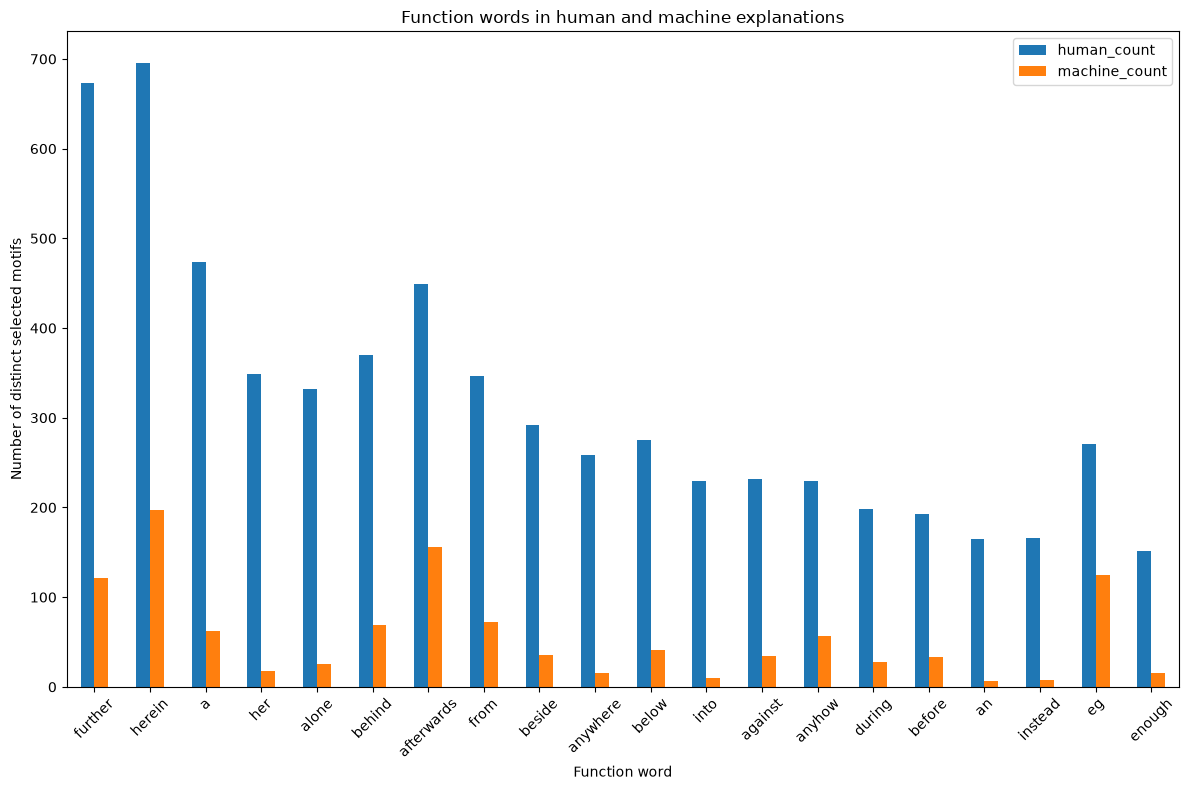

In [27]:
top_words = word_comparison.sort_values(
    "difference",
    key=abs,
    ascending=False
).head(20)

top_words = top_words.set_index("word")

top_words[["human_count", "machine_count"]].plot(
    kind="bar",
    figsize=(12,8)
)

plt.xlabel("Function word")
plt.ylabel("Number of distinct selected motifs")
plt.title("Function words in human and machine explanations")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Conclusion:
* Large differences in used words by machine and human graphs.

### 3. Uniformity of masks

In [38]:
def gini_coefficient(values):
    values = np.sort(np.asarray(values, dtype=float))

    n = len(values)

    if n == 0:
        return np.nan

    if np.sum(values) == 0:
        return 0.0

    return (
        2 * np.sum(np.arange(1, n + 1) * values)
        / (n * np.sum(values))
        - (n + 1) / n
    )


def summarize_edge_masks(df):

    rows = []

    for _, row in df.iterrows():

        mask = row["edge_mask"]

        if mask is None:
            continue

        values = mask.detach().cpu().numpy().flatten()

        if len(values) == 0:
            continue

        rows.append({
            "row": row["row"],
            "num_edges": len(values),
            "mean": np.mean(values),
            "std": np.std(values),
            "gini": gini_coefficient(values),
            "p90_p10": np.percentile(values, 90) - np.percentile(values, 10),
        })

    stats = pd.DataFrame(rows)

    # Aggregate summary
    print("\nSummary across all graphs:")
    print(
        stats[
            ["mean", "std", "gini", "p90_p10"]
        ].describe().round(3)
    )

    # Visualize
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    metrics = [
        ("std", "Standard deviation"),
        ("gini", "Gini coefficient"),
        ("p90_p10", "90th–10th percentile difference"),
    ]

    for ax, (metric, title) in zip(axes, metrics):

        sns.histplot(
            data=stats,
            x=metric,
            bins=25,
            kde=True,
            ax=ax,
        )

        ax.set_title(title)
        ax.set_ylabel("Number of graphs")

    plt.tight_layout()
    plt.show()

    return stats


Summary across all graphs:
          mean      std     gini  p90_p10
count  360.000  360.000  360.000  360.000
mean     0.151    0.089    0.166    0.116
std      0.081    0.097    0.145    0.226
min      0.082    0.002    0.015    0.002
25%      0.113    0.017    0.055    0.020
50%      0.122    0.021    0.065    0.024
75%      0.144    0.155    0.275    0.032
max      0.525    0.371    0.513    0.816


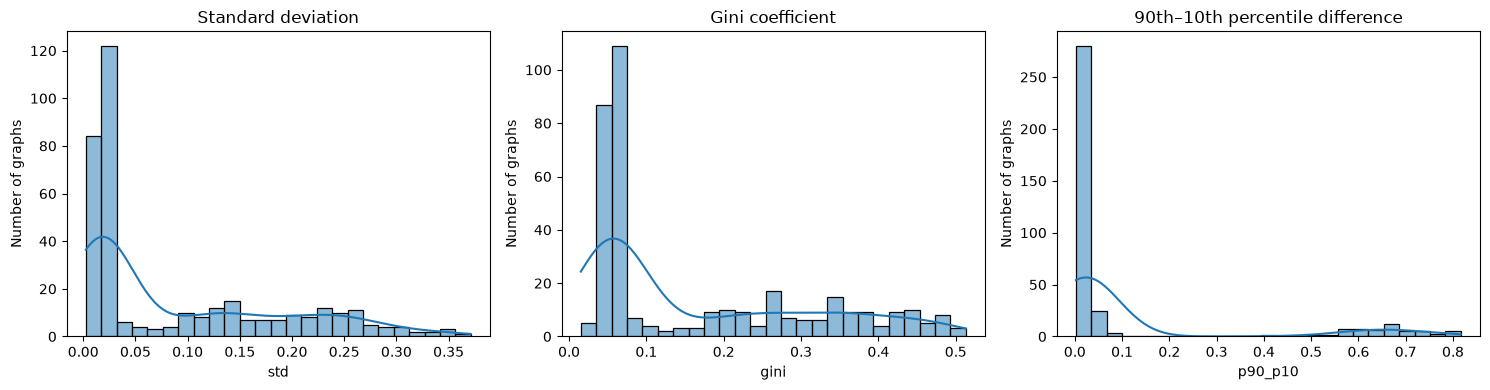

,row,num_edges,mean,std,gini,p90_p10
0,13,211,0.109410,0.010234,0.039895,0.018480
1,17,361,0.117684,0.018418,0.057058,0.021306
2,20,306,0.115315,0.018265,0.058330,0.020594
3,22,313,0.115925,0.017893,0.055152,0.020776
4,28,398,0.121092,0.016442,0.054432,0.024530
...,...,...,...,...,...,...
355,2372,57,0.373368,0.371205,0.499095,0.808040
356,2379,175,0.420350,0.297135,0.384054,0.656307
357,2381,205,0.146666,0.153881,0.275727,0.030479
358,2383,125,0.131266,0.142060,0.256212,0.019708


In [40]:
summarize_edge_masks(pd.DataFrame(results))